# Error analysis: LSTM vs MLP

## Setup

In [1]:
import importlib.util
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.sparse import csr_matrix, vstack
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

# Project 1's MLP code, loaded directly from its file (the part1 package imports more than we need)
spec = importlib.util.spec_from_file_location("smlp", "Project 1/part1/smlp.py")
smlp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(smlp)

MLP_DIR = "Project 1/results/mlp_indicator-lemmas"
LSTM_DIR = "results/final_lstm_s1_trial43"
SEEDS, FOLDS = [0, 1, 2], [0, 1, 2, 3, 4]

# colours: reference palette slots 1 (blue) and 2 (orange); identity also carried by marker shape and labels
COLORS = {"LSTM": "#2a78d6", "MLP": "#eb6834"}
MARKERS = {"LSTM": "o", "MLP": "s"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

In [2]:
# the same split as Project 1 and lstm_experiment.py: shuffle with seed 42, then a stratified 90/10 train/test split
df = pd.read_pickle("Pickles/merged_sampled_no_embeddings.pkl").sample(frac=1.0, random_state=42).reset_index(drop=True)
train_df, test_df = train_test_split(df, test_size=0.1, random_state=42, stratify=df.Party_orientation)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)

label_names = sorted(df.Party_orientation.unique())          # ['Left', 'Right']
gold = test_df.Party_orientation.map({n: i for i, n in enumerate(label_names)}).to_numpy()
as_text = lambda x: x if isinstance(x, str) else " ".join(x)
print(f"{len(train_df)} training sentences, {len(test_df)} test sentences")

454833 training sentences, 50537 test sentences


## Test predictions

In [3]:
# MLP: rebuild Project 1's token-indicator input (5,000 most frequent training lemmas, min count 5), then run its 15 models
lemma_counts = Counter(w for t in train_df.lemmas.map(as_text) for w in t.split())
mlp_vocab = {w: i for i, w in enumerate([w for w, c in lemma_counts.most_common(5000) if c >= 5])}
rows = []
for t in test_df.lemmas.map(as_text):
    idx = sorted({mlp_vocab[w] for w in t.split() if w in mlp_vocab})
    rows.append(csr_matrix((np.ones(len(idx), dtype=np.float32), idx, [0, len(idx)]), shape=(1, len(mlp_vocab))))
X_test = smlp.scipy_to_torch_sparse(vstack(rows))

mlp_probs = []
for seed in SEEDS:
    for fold in FOLDS:
        model = smlp.load(f"{MLP_DIR}/seed-{seed}/fold-{fold}/model", device="cpu").eval()
        with torch.no_grad():
            mlp_probs.append(model(X_test).exp().numpy())
mlp_probs = np.stack(mlp_probs)                               # [15 models, sentences, 2]

# check: the reloaded models reproduce Project 1's saved test scores
saved = pd.read_csv(f"{MLP_DIR}/test_scores.csv").sort_values(["seed", "fold"])
reproduced = [accuracy_score(gold, p.argmax(1)) for p in mlp_probs]
assert np.allclose(reproduced, saved.accuracy, atol=1e-9), "MLP predictions do not match Project 1"
print(f"MLP: 15 models reproduce Project 1's test accuracy {np.mean(reproduced):.4f}")

/Users/chrisfeltner/Git/nlp/nlp-project/Project 1/part1/smlp.py:81: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/chrisfeltner/Git/nlp/nlp-project/Project 1/part1/smlp.py:84: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


MLP: 15 models reproduce Project 1's test accuracy 0.7008


In [4]:
# LSTM: test predictions saved by the final runs (row_id = position in test_df)
lstm_probs = []
for seed in SEEDS:
    for fold in FOLDS:
        p = pd.read_csv(f"{LSTM_DIR}/seed-{seed}/fold-{fold}/test_predictions.csv").sort_values("row_id")
        assert (p.row_id.to_numpy() == np.arange(len(test_df))).all() and (p.gold == test_df.Party_orientation).all()
        lstm_probs.append(np.exp(p[[f"logprob_{n}" for n in label_names]].to_numpy()))
lstm_probs = np.stack(lstm_probs)

saved = pd.read_csv(f"{LSTM_DIR}/test_scores.csv").sort_values(["seed", "fold"])
reproduced = [accuracy_score(gold, p.argmax(1)) for p in lstm_probs]
assert np.allclose(reproduced, saved.accuracy, atol=1e-9), "LSTM predictions do not match its saved scores"
print(f"LSTM: 15 models, test accuracy {np.mean(reproduced):.4f}")

LSTM: 15 models, test accuracy 0.7245


## Sentence features

In [5]:
mlp_pred, lstm_pred = mlp_probs.argmax(2), lstm_probs.argmax(2)       # [15, sentences]
token_counts = Counter(w for toks in train_df.tokens for w in toks)

def word_features(tokens, lemmas):
    pairs = [(t, l) for t, l in zip(tokens, lemmas) if t.isalpha()]
    if not pairs:
        return np.nan, np.nan
    oov = np.mean([l not in mlp_vocab for _, l in pairs])
    freq = np.mean([np.log10(token_counts[t] + 1) for t, _ in pairs])
    return oov, freq

feats = [word_features(t, l) for t, l in zip(test_df.tokens, test_df.lemmas)]
sent = pd.DataFrame({
    "sentence": test_df.sentence, "gold": test_df.Party_orientation,
    "n_tokens": test_df.tokens.map(len),
    "mlp_oov_share": [f[0] for f in feats], "mean_log_freq": [f[1] for f in feats],
    "mlp_correct": (mlp_pred == gold).mean(0),                # share of the 15 MLP models that are right
    "lstm_correct": (lstm_pred == gold).mean(0),
    "mlp_vote": mlp_probs.mean(0).argmax(1), "lstm_vote": lstm_probs.mean(0).argmax(1),   # averaged ensembles
})
print(sent[["n_tokens", "mlp_oov_share", "mean_log_freq"]].describe().round(3).to_string())
print(f"\ncorrelation length vs MLP-unseen share: {sent.n_tokens.corr(sent.mlp_oov_share):+.3f}, "
      f"length vs mean word frequency: {sent.n_tokens.corr(sent.mean_log_freq):+.3f}, "
      f"unseen share vs mean word frequency: {sent.mlp_oov_share.corr(sent.mean_log_freq):+.3f}")

        n_tokens  mlp_oov_share  mean_log_freq
count  50537.000      50537.000      50537.000
mean      27.037          0.088          3.560
std       17.483          0.085          0.380
min        6.000          0.000          0.100
25%       14.000          0.000          3.344
50%       23.000          0.075          3.575
75%       35.000          0.133          3.789
max      259.000          1.000          5.174

correlation length vs MLP-unseen share: +0.037, length vs mean word frequency: -0.043, unseen share vs mean word frequency: -0.644


## Overall

In [6]:
def scores(mask=None):
    m = np.ones(len(sent), bool) if mask is None else np.asarray(mask)
    out = {}
    for name, pred in (("MLP", mlp_pred), ("LSTM", lstm_pred)):
        out[f"{name} acc"] = np.mean([accuracy_score(gold[m], p[m]) for p in pred])
        out[f"{name} F1"] = np.mean([f1_score(gold[m], p[m], average="macro") for p in pred])
    return out

print(pd.Series(scores()).round(4).to_string())

# who gets which sentences right (averaged ensembles of 15 models each)
m_ok, l_ok = sent.mlp_vote == gold, sent.lstm_vote == gold
agree = pd.crosstab(m_ok.map({True: "MLP right", False: "MLP wrong"}), l_ok.map({True: "LSTM right", False: "LSTM wrong"}),
                    normalize="all").round(3)
print("\nshare of test sentences (ensembles):"); print(agree.to_string())
print(f"\nthe LSTM fixes {np.mean(~m_ok & l_ok):.1%} of sentences and breaks {np.mean(m_ok & ~l_ok):.1%}: "
      f"net {np.mean(l_ok) - np.mean(m_ok):+.1%}")

MLP acc     0.7008
MLP F1      0.6648
LSTM acc    0.7245
LSTM F1     0.7032

share of test sentences (ensembles):
lstm_vote  LSTM right  LSTM wrong
mlp_vote                         
MLP right       0.633       0.073
MLP wrong       0.108       0.186

the LSTM fixes 10.8% of sentences and breaks 7.3%: net +3.4%


In [7]:
def by_group(groups, order):
    """Accuracy and macro F1 of both systems per group, and the LSTM - MLP accuracy difference with a 95% CI."""
    rows = []
    for g in order:
        m = (groups == g).to_numpy()
        d = sent.lstm_correct[m] - sent.mlp_correct[m]          # per-sentence paired difference
        s = scores(m)
        rows.append({"group": g, "n": int(m.sum()), "share": m.mean(),
                     "MLP acc": s["MLP acc"], "LSTM acc": s["LSTM acc"],
                     "diff": d.mean(), "ci": 1.96 * d.std() / np.sqrt(m.sum()),
                     "MLP F1": s["MLP F1"], "LSTM F1": s["LSTM F1"]})
    return pd.DataFrame(rows)

def plot_groups(table, title, xlabel):
    """Left: accuracy per group for both systems. Right: LSTM - MLP difference with 95% CI."""
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
    x = np.arange(len(table))
    for name in ("MLP", "LSTM"):
        a.plot(x, table[f"{name} acc"], color=COLORS[name], marker=MARKERS[name], markersize=7, linewidth=2,
               label=name, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
        a.annotate(name, (x[-1], table[f"{name} acc"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                   va="center", color=INK, fontsize=9)
    a.set_xticks(x, table.group, rotation=0); a.set_ylabel("accuracy"); a.set_xlabel(xlabel)
    a.grid(axis="y", color=GRID, linewidth=0.8); a.set_axisbelow(True)
    a.set_xlim(-0.3, len(table) - 0.4)   # room for the direct labels at the right end
    handles, labels = a.get_legend_handles_labels()
    a.set_title(title, loc="left", color=INK, fontsize=11)
    b.bar(x, table["diff"] * 100, color=COLORS["LSTM"], width=0.6, yerr=table.ci * 100, ecolor=INK_2, capsize=3)
    b.axhline(0, color=INK_2, linewidth=1)
    b.set_xticks(x, table.group); b.set_ylabel("LSTM - MLP accuracy (points)"); b.set_xlabel(xlabel)
    b.grid(axis="y", color=GRID, linewidth=0.8); b.set_axisbelow(True)
    b.set_title("LSTM advantage, with 95% CI", loc="left", color=INK, fontsize=11)
    # legend in its own row below the charts, so it never covers data or titles
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

def show(table):
    t = table.copy()
    t["share"] = (t.share * 100).round(1).astype(str) + "%"
    t["diff ± CI (points)"] = (t["diff"] * 100).round(1).astype(str) + " ± " + (t.ci * 100).round(1).astype(str)
    print(t.drop(columns=["diff", "ci"]).round(3).to_string(index=False))

## Sentence length

group     n share  MLP acc  LSTM acc  MLP F1  LSTM F1 diff ± CI (points)
  ≤10  7366 14.6%    0.636     0.641   0.596    0.623          0.5 ± 0.8
11-15  6990 13.8%    0.670     0.700   0.630    0.681          3.0 ± 0.8
16-20  7284 14.4%    0.695     0.722   0.661    0.702          2.7 ± 0.7
21-30 12078 23.9%    0.710     0.737   0.673    0.714          2.8 ± 0.6
31-40  7812 15.5%    0.725     0.751   0.689    0.727          2.6 ± 0.7
41-60  6425 12.7%    0.741     0.767   0.710    0.746          2.5 ± 0.7
  >60  2582  5.1%    0.769     0.790   0.742    0.770          2.1 ± 1.1


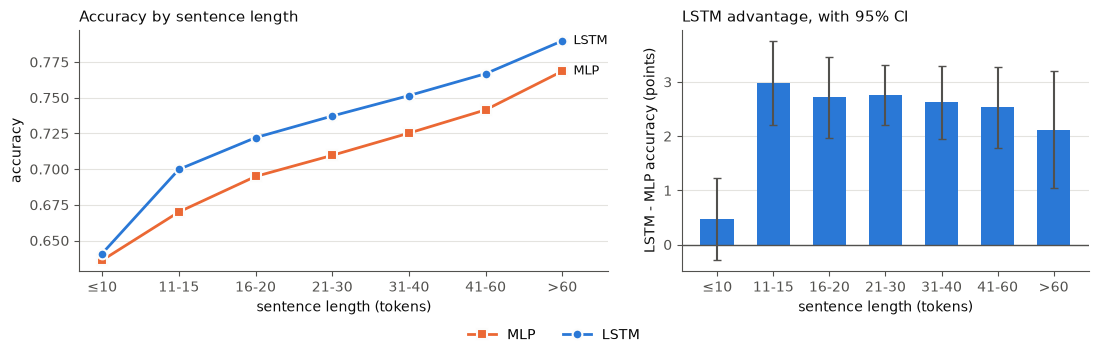

In [8]:
length_order = ["≤10", "11-15", "16-20", "21-30", "31-40", "41-60", ">60"]
length_group = pd.cut(sent.n_tokens, [0, 10, 15, 20, 30, 40, 60, np.inf], labels=length_order)
length_table = by_group(length_group, length_order)
show(length_table)
plot_groups(length_table, "Accuracy by sentence length", "sentence length (tokens)")

## Word frequency

### Out-of-vocabulary words

 group     n share  MLP acc  LSTM acc  MLP F1  LSTM F1 diff ± CI (points)
    0% 13379 26.5%    0.680     0.691   0.647    0.673          1.1 ± 0.5
 1-10% 18793 37.2%    0.712     0.738   0.685    0.722          2.6 ± 0.4
11-20% 14104 27.9%    0.708     0.735   0.663    0.707          2.7 ± 0.5
21-30%  3211  6.4%    0.704     0.740   0.639    0.699          3.6 ± 1.2
  >30%  1050  2.1%    0.654     0.711   0.580    0.676          5.7 ± 2.3


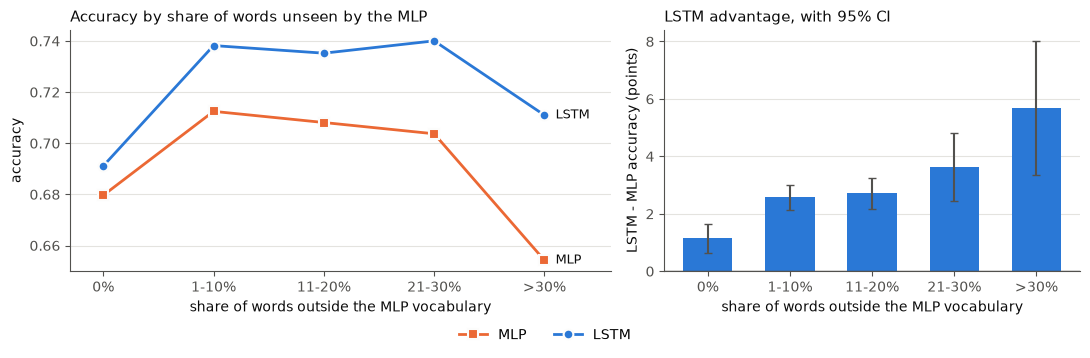

In [9]:
oov_order = ["0%", "1-10%", "11-20%", "21-30%", ">30%"]
oov_group = pd.cut(sent.mlp_oov_share, [-0.001, 0, 0.1, 0.2, 0.3, 1.0], labels=oov_order)
oov_table = by_group(oov_group, oov_order)
show(oov_table)
plot_groups(oov_table, "Accuracy by share of words unseen by the MLP", "share of words outside the MLP vocabulary")

### Mean log frequency

          group     n share  MLP acc  LSTM acc  MLP F1  LSTM F1 diff ± CI (points)
     Q1\nrarest 10108 20.0%    0.715     0.739   0.646    0.692          2.4 ± 0.6
             Q2 10107 20.0%    0.721     0.742   0.672    0.709          2.1 ± 0.6
             Q3 10107 20.0%    0.713     0.736   0.675    0.713          2.2 ± 0.6
             Q4 10107 20.0%    0.688     0.716   0.668    0.706          2.8 ± 0.6
Q5\nmost common 10108 20.0%    0.667     0.690   0.650    0.683          2.3 ± 0.6


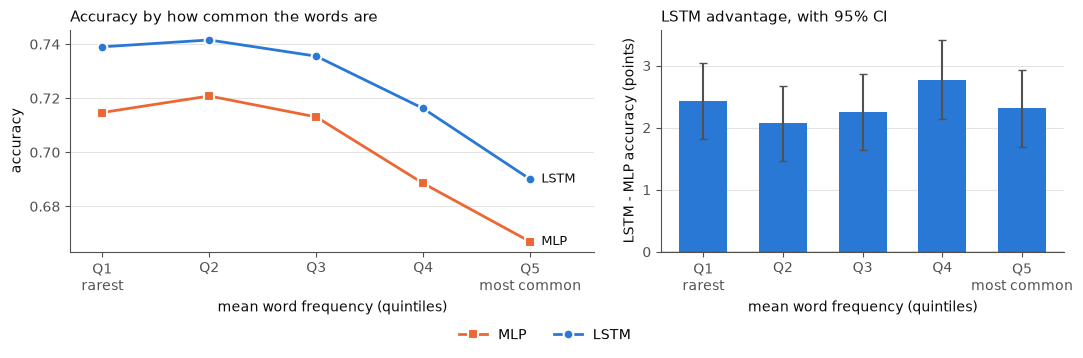

In [10]:
freq_order = ["Q1\nrarest", "Q2", "Q3", "Q4", "Q5\nmost common"]
freq_group = pd.qcut(sent.mean_log_freq, 5, labels=freq_order)
freq_table = by_group(freq_group, freq_order)
show(freq_table)
plot_groups(freq_table, "Accuracy by how common the words are", "mean word frequency (quintiles)")

## Length and out-of-vocabulary words

In [11]:
len3 = pd.cut(sent.n_tokens, [0, 15, 30, np.inf], labels=["≤15 tokens", "16-30", ">30"])
oov3 = pd.cut(sent.mlp_oov_share, [-0.001, 0.05, 0.2, 1.0], labels=["≤5% unseen", "5-20%", ">20%"])
grid = sent.assign(len3=len3, oov3=oov3, diff=(sent.lstm_correct - sent.mlp_correct) * 100)
print("LSTM - MLP accuracy difference (points):")
print(grid.pivot_table(index="len3", columns="oov3", values="diff", aggfunc="mean", observed=False).round(1).to_string())
print("\nnumber of sentences:")
print(grid.pivot_table(index="len3", columns="oov3", values="diff", aggfunc="size", observed=False).to_string())

LSTM - MLP accuracy difference (points):
oov3        ≤5% unseen  5-20%  >20%
len3                               
≤15 tokens         0.6    2.4   4.8
16-30              2.1    2.9   4.2
>30                2.8    2.4   3.0

number of sentences:
oov3        ≤5% unseen  5-20%  >20%
len3                               
≤15 tokens        7739   5050  1567
16-30             6488  11137  1737
>30               4764  11098   957


## Examples

In [12]:
def examples(mask, n=6):
    s = sent[mask].sample(min(n, int(mask.sum())), random_state=0)
    for _, r in s.iterrows():
        print(f"[{r.gold:5}] {r.n_tokens:3d} tokens, {r.mlp_oov_share:.0%} unseen by MLP | {r.sentence[:150]}")

lstm_wins = (sent.lstm_correct >= 0.8) & (sent.mlp_correct <= 0.2)
mlp_wins = (sent.mlp_correct >= 0.8) & (sent.lstm_correct <= 0.2)
print(f"LSTM clearly better on {lstm_wins.mean():.1%} of sentences, MLP clearly better on {mlp_wins.mean():.1%}\n")
print("LSTM right, MLP wrong:"); examples(lstm_wins)
print("\nMLP right, LSTM wrong:"); examples(mlp_wins)
print("\nmedian length and unseen share:")
print(pd.DataFrame({"LSTM wins": sent[lstm_wins][["n_tokens", "mlp_oov_share"]].median(),
                    "MLP wins": sent[mlp_wins][["n_tokens", "mlp_oov_share"]].median(),
                    "all": sent[["n_tokens", "mlp_oov_share"]].median()}).round(3).to_string())

LSTM clearly better on 4.3% of sentences, MLP clearly better on 2.4%

LSTM right, MLP wrong:
[Left ]  13 tokens, 10% unseen by MLP | Azt mondják, hogy majd ha visszamész a helyedre, akkor megkapod!
[Left ]  66 tokens, 8% unseen by MLP | Egy picit hadd menjek elébe az „ elmúltnyolcévezésnek”, hiszen mi már tavaly is mondtuk, akkor, amikor az NMHH költségvetéséről beszéltünk, amikor az 
[Right]  20 tokens, 6% unseen by MLP | Ott lesz az a lényeges elem, hogy melyik kategóriában milyen támogatási rendszer lesz, és hogyan tudunk továbblépni.
[Left ]  39 tokens, 0% unseen by MLP | Van persze természetesen néhány olyan elem, ami nem teljesen érthető, hogy miért van a csomagban, ezek azonban talán szám szerint kevesebben vannak, i
[Right]  36 tokens, 17% unseen by MLP | Odaküldtek nem egy szervezetet, nem kettőt, most éppen a máltaiak vannak Tiszabőn, próbálnak rendet tenni, de egyszerűen képtelenség átgondolt, jól me
[Left ]  31 tokens, 11% unseen by MLP | Dicséretes törekvés a teljes foglal

## Word order

In [13]:
import lstm_experiment as lx

device = lx.pick_device("auto")
tokenizer, hubert_emb = lx.hubert_embedding_matrix("SZTAKI-HLT/hubert-base-cc")
pad_id = tokenizer.pad_token_id
lstm_models = {(s, f): lx.load_model_pkl(f"{LSTM_DIR}/seed-{s}/fold-{f}/model.pkl", device, hubert_emb)[0]
               for s in SEEDS for f in FOLDS}
MAX_LEN = 256  # as in training (lstm_experiment.py default, also in the saved configs)

def lstm_logprobs(model, texts):
    """Tokenize like lstm_experiment.tokenize (no cache) and return log-probabilities [sentences, 2]."""
    ids = tokenizer(texts, add_special_tokens=False, truncation=True, max_length=MAX_LEN)["input_ids"]
    ids = [x if x else [tokenizer.unk_token_id] for x in ids]
    _, _, _, logprobs = lx.predict(model, lx.LabelledSequences(ids, gold.tolist()), pad_id, 512, device)
    return logprobs

def shuffle_words(text, rng):
    words = text.split()
    rng.shuffle(words)
    return " ".join(words)

texts = test_df.sentence.tolist()
original_pred, shuffled_pred = [], []
for i, ((s, f), model) in enumerate(lstm_models.items()):
    with torch.no_grad():
        original_pred.append(lstm_logprobs(model, texts).argmax(1))
        rng = random.Random(1000 + i)  # a different shuffle for each model
        shuffled_pred.append(lstm_logprobs(model, [shuffle_words(t, rng) for t in texts]).argmax(1))
original_pred, shuffled_pred = np.stack(original_pred), np.stack(shuffled_pred)

# sanity check: same predictions as the saved test_predictions.csv (tiny numeric differences between GPUs allowed)
same = (original_pred == lstm_pred).mean()
print(f"unshuffled pipeline agrees with the saved LSTM predictions on {same:.4%} of (model, sentence) pairs")
assert same > 0.999

W1121 17:27:55.250000 23888 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SZTAKI-HLT/hubert-base-cc
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


unshuffled pipeline agrees with the saved LSTM predictions on 99.9959% of (model, sentence) pairs


In [14]:
def acc_f1(pred, m=None):
    m = np.ones(len(gold), bool) if m is None else np.asarray(m)
    return (np.array([accuracy_score(gold[m], p[m]) for p in pred]),
            np.array([f1_score(gold[m], p[m], average="macro") for p in pred]))

rows = {}
for name, pred in (("MLP (order-free)", mlp_pred), ("LSTM", lstm_pred), ("LSTM, shuffled words", shuffled_pred)):
    a, f = acc_f1(pred)
    rows[name] = {"accuracy": a.mean(), "acc std": a.std(ddof=1), "macro F1": f.mean(), "F1 std": f.std(ddof=1)}
print(pd.DataFrame(rows).T.round(4).to_string())

a_o, f_o = acc_f1(lstm_pred); a_s, f_s = acc_f1(shuffled_pred); a_m, f_m = acc_f1(mlp_pred)
print(f"\nshuffling costs the LSTM {100 * (a_o - a_s).mean():.2f} accuracy / {100 * (f_o - f_s).mean():.2f} F1 points "
      f"(range over 15 models: {100 * (a_o - a_s).min():.2f} to {100 * (a_o - a_s).max():.2f} accuracy)")
print(f"that is {(a_o - a_s).mean() / (a_o - a_m).mean():.0%} of its accuracy lead over the MLP "
      f"and {(f_o - f_s).mean() / (f_o - f_m).mean():.0%} of its F1 lead")
print(f"shuffled LSTM vs MLP: {100 * (a_s - a_m).mean():+.2f} accuracy / {100 * (f_s - f_m).mean():+.2f} F1 points")
changed = (shuffled_pred != lstm_pred).mean()
print(f"the shuffle changes the LSTM's prediction on {changed:.1%} of (model, sentence) pairs")

                      accuracy  acc std  macro F1  F1 std
MLP (order-free)        0.7008   0.0014    0.6648  0.0036
LSTM                    0.7245   0.0025    0.7032  0.0038
LSTM, shuffled words    0.7003   0.0032    0.6751  0.0038



shuffling costs the LSTM 2.42 accuracy / 2.80 F1 points (range over 15 models: 1.88 to 2.79 accuracy)
that is 102% of its accuracy lead over the MLP and 73% of its F1 lead
shuffled LSTM vs MLP: -0.05 accuracy / +1.04 F1 points
the shuffle changes the LSTM's prediction on 15.2% of (model, sentence) pairs


### By sentence length

group     n   MLP  LSTM  LSTM, shuffled  changed  order effect (points)  LSTM lead (points)
  ≤10  7366 0.636 0.641           0.616    0.181                  2.467               0.473
11-15  6990 0.670 0.700           0.678    0.154                  2.199               2.980
16-20  7284 0.695 0.722           0.699    0.155                  2.281               2.716
21-30 12078 0.710 0.737           0.713    0.149                  2.381               2.753
31-40  7812 0.725 0.751           0.726    0.142                  2.591               2.626
41-60  6425 0.741 0.767           0.741    0.140                  2.566               2.534
  >60  2582 0.769 0.790           0.764    0.132                  2.561               2.122


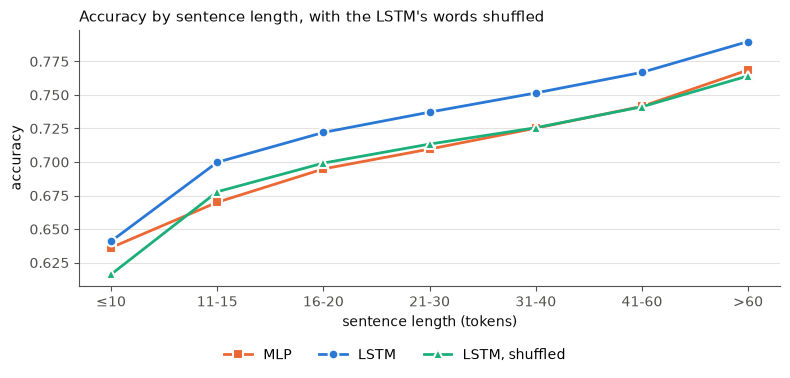

In [15]:
COLORS["LSTM, shuffled"] = "#1baf7a"   # palette slot 3 (aqua)
MARKERS["LSTM, shuffled"] = "^"

order_rows = []
for g in length_order:
    m = (length_group == g).to_numpy()
    order_rows.append({"group": g, "n": int(m.sum()),
                       "MLP": acc_f1(mlp_pred, m)[0].mean(), "LSTM": acc_f1(lstm_pred, m)[0].mean(),
                       "LSTM, shuffled": acc_f1(shuffled_pred, m)[0].mean(),
                       "changed": (shuffled_pred[:, m] != lstm_pred[:, m]).mean()})
order_table = pd.DataFrame(order_rows)
order_table["order effect (points)"] = 100 * (order_table["LSTM"] - order_table["LSTM, shuffled"])
order_table["LSTM lead (points)"] = 100 * (order_table["LSTM"] - order_table["MLP"])
print(order_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(order_table))
for name in ("MLP", "LSTM", "LSTM, shuffled"):
    ax.plot(x, order_table[name], color=COLORS[name], marker=MARKERS[name], markersize=7, linewidth=2, label=name,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.set_xticks(x, order_table.group); ax.set_xlabel("sentence length (tokens)"); ax.set_ylabel("accuracy")
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Accuracy by sentence length, with the LSTM's words shuffled", loc="left", color=INK, fontsize=11)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

### Shuffle results

## Named entities

In [16]:
from pathlib import Path

NAME_TYPES = ("PER", "ORG")   # people and organisations

def read_conllu_ner(conllu_dir, wanted_docs):
    """{(speech id, sentence text): (forms, NER tags)} for every sentence of the wanted speeches."""
    out = {}
    for path in sorted(Path(conllu_dir).rglob("*.conllu")):
        keep, text = False, None
        with open(path, encoding="utf-8") as f:
            for line in f:
                if line.startswith("# newdoc id = "):
                    doc = line[14:].strip()
                    keep = doc in wanted_docs
                elif not keep:
                    continue
                elif line.startswith("# text = "):
                    text, forms, tags = line[9:].rstrip("\n"), [], []
                elif line == "\n":
                    if text is not None:
                        out.setdefault((doc, text), (forms, tags))
                    text = None
                elif line[0].isdigit():
                    cols = line.rstrip("\n").split("\t")
                    if "-" in cols[0] or "." in cols[0]:      # multiword / empty tokens
                        continue
                    forms.append(cols[1])
                    tags.append(next((m[4:] for m in cols[9].split("|") if m.startswith("NER=")), "O"))
    return out

conllu = read_conllu_ner("Dataset/ParlaMint-HU/ParlaMint-HU.conllu", set(test_df.join_key))
matched = [conllu.get((k, s)) for k, s in zip(test_df.join_key, test_df.sentence)]
print(f"matched {sum(m is not None for m in matched)} of {len(test_df)} test sentences to CoNLL-U")
assert all(m is not None for m in matched)
test_forms = [m[0] for m in matched]
test_tags = [m[1] for m in matched]

def entities(forms, tags):
    """[(type, text), ...] from IOB tags"""
    ents = []
    for w, t in zip(forms, tags):
        if t.startswith("B-") or (t.startswith("I-") and (not ents or ents[-1][0] != t[2:])):
            ents.append([t[2:], w])
        elif t.startswith("I-"):
            ents[-1][1] += " " + w
    return [tuple(e) for e in ents]

test_ents = [entities(f, t) for f, t in zip(test_forms, test_tags)]
for typ in ("PER", "ORG", "LOC", "MISC"):
    sent[f"has_{typ}"] = [any(t == typ for t, _ in e) for e in test_ents]
sent["has_name"] = sent.has_PER | sent.has_ORG
sent["name_kind"] = np.select([sent.has_PER & sent.has_ORG, sent.has_PER, sent.has_ORG],
                              ["person + org", "person only", "org only"], "no name")
print(sent[["has_PER", "has_ORG", "has_LOC", "has_MISC", "has_name"]].mean().round(3).to_string())

matched 50537 of 50537 test sentences to CoNLL-U


has_PER     0.083
has_ORG     0.156
has_LOC     0.098
has_MISC    0.025
has_name    0.220


In [17]:
# the most frequent names, and how one-sided they are (share of Left among the test sentences that mention them)
rows = [(typ, name, g) for e, g in zip(test_ents, test_df.Party_orientation) for typ, name in set(e) if typ in NAME_TYPES]
names = pd.DataFrame(rows, columns=["type", "name", "gold"])
top = (names.groupby(["type", "name"]).gold.agg(n="size", left_share=lambda g: (g == "Left").mean())
       .reset_index().sort_values("n", ascending=False))
print(f"overall share of Left in the test set: {(test_df.Party_orientation == 'Left').mean():.3f}\n")
for typ in NAME_TYPES:
    print(f"most frequent {typ}:")
    print(top[top.type == typ].head(12).round(3).to_string(index=False)); print()

overall share of Left in the test set: 0.379

most frequent PER:
type             name   n  left_share
 PER     Orbán Viktor 238       0.672
 PER Gyurcsány Ferenc  99       0.030
 PER      Államtitkár  58       0.328
 PER      Lázár János  50       0.560
 PER            Nacsa  46       0.804
 PER  Mészáros Lőrinc  45       0.622
 PER Z. Kárpát Dániel  41       0.341
 PER  Matolcsy György  36       0.694
 PER       Kósa Lajos  30       0.533
 PER     Varga Mihály  30       0.600
 PER  Szijjártó Péter  29       0.621
 PER      Rogán Antal  29       0.517

most frequent ORG:
type                      name   n  left_share
 ORG              Magyarország 638       0.248
 ORG                    Fidesz 448       0.585
 ORG                    Jobbik 406       0.118
 ORG              Országgyűlés 390       0.300
 ORG              Európai Unió 321       0.209
 ORG                       Ház 202       0.347
 ORG                       LMP 187       0.775
 ORG                      MSZP 177       0.44

### With and without names

   group     n share  MLP acc  LSTM acc  MLP F1  LSTM F1 diff ± CI (points)
 no name 39411 78.0%    0.690     0.714   0.653    0.692          2.4 ± 0.3
has name 11126 22.0%    0.738     0.761   0.707    0.742          2.4 ± 0.5


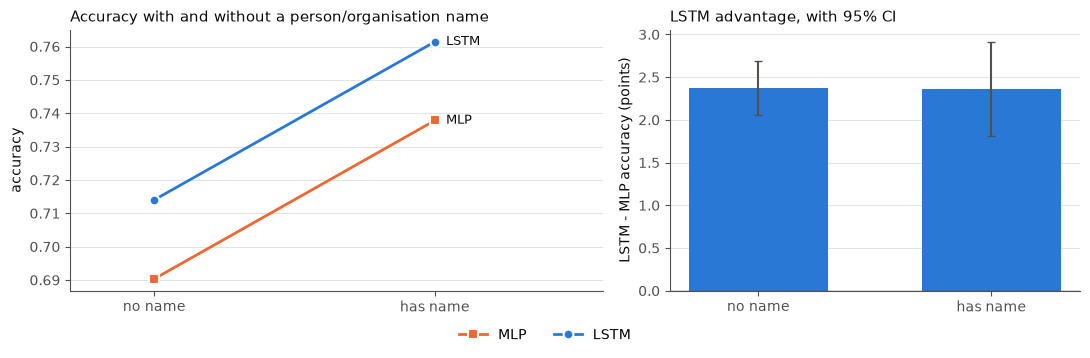

       group     n share  MLP acc  LSTM acc  MLP F1  LSTM F1 diff ± CI (points)
     no name 39411 78.0%    0.690     0.714   0.653    0.692          2.4 ± 0.3
 person only  3249  6.4%    0.698     0.719   0.681    0.710          2.1 ± 1.1
    org only  6912 13.7%    0.758     0.783   0.715    0.755          2.5 ± 0.7
person + org   965  1.9%    0.729     0.752   0.717    0.746          2.3 ± 1.8


In [18]:
name_order = ["no name", "has name"]
name_group = sent.has_name.map({False: "no name", True: "has name"})
name_table = by_group(name_group, name_order)
show(name_table)
plot_groups(name_table, "Accuracy with and without a person/organisation name", "")

kind_order = ["no name", "person only", "org only", "person + org"]
kind_table = by_group(sent.name_kind, kind_order)
show(kind_table)

In [19]:
len4 = pd.cut(sent.n_tokens, [0, 15, 30, 60, np.inf], labels=["≤15", "16-30", "31-60", ">60"])
g = sent.assign(len4=len4, name=name_group, diff=(sent.lstm_correct - sent.mlp_correct) * 100)
print(f"share of sentences with a name: {sent.has_name.mean():.1%}; by length band:")
print(g.groupby("len4", observed=True).has_name.mean().round(3).to_string())
for value, label in (("diff", "LSTM - MLP (points)"), ("mlp_correct", "MLP accuracy"), ("lstm_correct", "LSTM accuracy")):
    print(f"\n{label}:")
    print(g.pivot_table(index="len4", columns="name", values=value, aggfunc="mean", observed=True)[name_order]
          .round(3 if value != "diff" else 1).to_string())

share of sentences with a name: 22.0%; by length band:
len4
≤15      0.107
16-30    0.213
31-60    0.306
>60      0.424

LSTM - MLP (points):
name   no name  has name
len4                    
≤15        1.7       1.7
16-30      2.6       3.1
31-60      2.7       2.2
>60        3.1       0.8

MLP accuracy:
name   no name  has name
len4                    
≤15      0.645     0.715
16-30    0.698     0.726
31-60    0.726     0.747
>60      0.762     0.777

LSTM accuracy:
name   no name  has name
len4                    
≤15      0.662     0.732
16-30    0.724     0.758
31-60    0.754     0.769
>60      0.793     0.785


### Name removal

In [20]:
ner_rows = np.flatnonzero(sent.has_name.to_numpy())
aligned = np.array([len(test_forms[i]) == len(test_df.lemmas[i]) for i in ner_rows])
print(f"{len(ner_rows)} sentences with a name; CoNLL-U tokens align with our lemmas for {aligned.mean():.2%}")
ner_rows = ner_rows[aligned]

rng_rm = np.random.default_rng(0)
keep_names_removed, keep_control = [], []
for i in ner_rows:
    is_name = np.array([t[2:] in NAME_TYPES if t != "O" else False for t in test_tags[i]])
    other = np.flatnonzero(~is_name & np.array([any(ch.isalnum() for ch in w) for w in test_forms[i]]))
    drop = rng_rm.choice(other, min(is_name.sum(), len(other)), replace=False)
    ctrl = np.ones(len(is_name), bool); ctrl[drop] = False
    keep_names_removed.append(~is_name); keep_control.append(ctrl)

def rebuild_text(i, keep):
    return " ".join(w for w, k in zip(test_forms[i], keep) if k)

def mlp_input(lemma_lists):
    rows = []
    for lemmas in lemma_lists:
        idx = sorted({mlp_vocab[w] for w in lemmas if w in mlp_vocab})
        rows.append(csr_matrix((np.ones(len(idx), dtype=np.float32), idx, [0, len(idx)]), shape=(1, len(mlp_vocab))))
    return smlp.scipy_to_torch_sparse(vstack(rows))

variants = {
    "original": ([rebuild_text(i, np.ones(len(test_forms[i]), bool)) for i in ner_rows],
                 [list(test_df.lemmas[i]) for i in ner_rows]),
    "names removed": ([rebuild_text(i, k) for i, k in zip(ner_rows, keep_names_removed)],
                      [[l for l, k in zip(test_df.lemmas[i], keep) if k] for i, keep in zip(ner_rows, keep_names_removed)]),
    "control (random words removed)": ([rebuild_text(i, k) for i, k in zip(ner_rows, keep_control)],
                                       [[l for l, k in zip(test_df.lemmas[i], keep) if k] for i, keep in zip(ner_rows, keep_control)]),
}
print("example:", variants["original"][0][0][:120])
print("  names removed:", variants["names removed"][0][0][:120])
print("  control:      ", variants["control (random words removed)"][0][0][:120])

gold_ner = gold[ner_rows]
def lstm_logprobs_rows(model, texts):
    ids = tokenizer(texts, add_special_tokens=False, truncation=True, max_length=MAX_LEN)["input_ids"]
    ids = [x if x else [tokenizer.unk_token_id] for x in ids]
    return lx.predict(model, lx.LabelledSequences(ids, gold_ner.tolist()), pad_id, 512, device)[3]

removal_pred = {}
for vname, (texts_v, lemmas_v) in variants.items():
    X_v = mlp_input(lemmas_v)
    mp, lp = [], []
    for s in SEEDS:
        for f in FOLDS:
            with torch.no_grad():
                mp.append(smlp.load(f"{MLP_DIR}/seed-{s}/fold-{f}/model", device="cpu").eval()(X_v).exp().numpy().argmax(1))
                lp.append(lstm_logprobs_rows(lstm_models[(s, f)], texts_v).argmax(1))
    removal_pred[vname] = {"MLP": np.stack(mp), "LSTM": np.stack(lp)}

# sanity check: the rebuilt, unmodified sentences give the same predictions as the original pipeline
for name, ref in (("MLP", mlp_pred), ("LSTM", lstm_pred)):
    agree = (removal_pred["original"][name] == ref[:, ner_rows]).mean()
    print(f"{name}: rebuilt sentences agree with the original predictions on {agree:.3%}")
    assert agree > 0.99

11126 sentences with a name; CoNLL-U tokens align with our lemmas for 100.00%


example: Tehát Polt Péter legfőbb ügyész úr volt .
  names removed: Tehát legfőbb ügyész úr volt .
  control:       Tehát Polt Péter legfőbb ügyész .


MLP: rebuilt sentences agree with the original predictions on 100.000%
LSTM: rebuilt sentences agree with the original predictions on 99.997%


In [21]:
rows = []
for name in ("MLP", "LSTM"):
    base = np.array([accuracy_score(gold_ner, p) for p in removal_pred["original"][name]])
    for vname in variants:
        a = np.array([accuracy_score(gold_ner, p) for p in removal_pred[vname][name]])
        f = np.array([f1_score(gold_ner, p, average="macro") for p in removal_pred[vname][name]])
        d = 100 * (a - base)
        rows.append({"system": name, "version": vname, "accuracy": a.mean(), "macro F1": f.mean(),
                     "change (points)": d.mean(), "change, min": d.min(), "change, max": d.max(),
                     "predictions changed": (removal_pred[vname][name] != removal_pred["original"][name]).mean()})
removal_table = pd.DataFrame(rows)
print(f"{len(ner_rows)} test sentences with a person or organisation name, 15 models per system")
print(removal_table.round(4).to_string(index=False))

# the effect of the names themselves: drop with names removed beyond the control drop, per model
for name in ("MLP", "LSTM"):
    n = np.array([accuracy_score(gold_ner, p) for p in removal_pred["names removed"][name]])
    c = np.array([accuracy_score(gold_ner, p) for p in removal_pred["control (random words removed)"][name]])
    d = 100 * (n - c)
    print(f"{name}: names removed vs control: {d.mean():+.2f} points (15 models: {d.min():+.2f} to {d.max():+.2f})")

11126 test sentences with a person or organisation name, 15 models per system
system                        version  accuracy  macro F1  change (points)  change, min  change, max  predictions changed
   MLP                       original    0.7378    0.7068           0.0000       0.0000       0.0000               0.0000
   MLP                  names removed    0.6981    0.6523          -3.9715      -4.4131      -3.4514               0.1243
   MLP control (random words removed)    0.7362    0.7046          -0.1648      -0.4045       0.1079               0.0487
  LSTM                       original    0.7614    0.7422           0.0000       0.0000       0.0000               0.0000
  LSTM                  names removed    0.7161    0.6848          -4.5353      -4.7816      -4.1974               0.1501
  LSTM control (random words removed)    0.7557    0.7363          -0.5722      -0.8988      -0.3236               0.0516
MLP: names removed vs control: -3.81 points (15 models: -4.22 to -3.

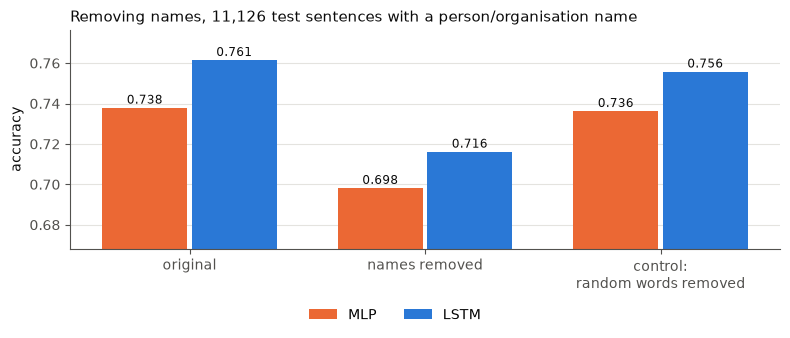

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(3)
for k, name in enumerate(("MLP", "LSTM")):
    t = removal_table[removal_table.system == name]
    ax.bar(x + (k - 0.5) * 0.38, t.accuracy, width=0.36, color=COLORS[name], label=name)
    for xi, v in zip(x, t.accuracy):
        ax.annotate(f"{v:.3f}", (xi + (k - 0.5) * 0.38, v), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8.5, color=INK)
lo = removal_table.accuracy.min()
ax.set_ylim(lo - 0.03, removal_table.accuracy.max() + 0.015)
ax.set_xticks(x, ["original", "names removed", "control:\nrandom words removed"])
ax.set_ylabel("accuracy"); ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title(f"Removing names, {len(ner_rows):,} test sentences with a person/organisation name",
             loc="left", color=INK, fontsize=11)
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

### Named entity results

## Bayesian regression

In [23]:
import arviz as az

# the tutorial's BDA code, loaded from its file (importing the part2 package would also load the training code)
spec = importlib.util.spec_from_file_location("bda", "part2/analysis.py")
bda = importlib.util.module_from_spec(spec)
spec.loader.exec_module(bda)

SYSTEM_NAMES = ["MLP", "LSTM"]
FEATURES = ["log_length", "mlp_oov_share", "mean_log_freq", "has_PER", "has_ORG"]
FEATURE_NAMES = ["pred:Left"] + FEATURES
FEATURE_LABELS = {   # descriptive names for the plots and tables
    "pred:Left": "predicted Left",
    "log_length": "sentence length (log tokens)",
    "mlp_oov_share": "share of words unknown to the MLP",
    "mean_log_freq": "mean word frequency in training (log)",
    "has_PER": "contains a person name",
    "has_ORG": "contains an organisation name",
}
LABELS = [FEATURE_LABELS[f] for f in FEATURE_NAMES]

rng = np.random.default_rng(0)
usable = np.flatnonzero(sent[["mlp_oov_share", "mean_log_freq"]].notna().all(axis=1).to_numpy())  # has words
idx = np.sort(rng.choice(usable, 20_000, replace=False))
left = label_names.index("Left")

parts = []
for sid, (name, pred) in enumerate((("MLP", mlp_pred), ("LSTM", lstm_pred))):
    model_of = rng.integers(0, pred.shape[0], len(idx))       # one random model of the 15 per sentence
    p = pred[model_of, idx]
    parts.append(pd.DataFrame({
        "system_id": sid, "system": name, "row": idx, "model": model_of,
        "correct": (p == gold[idx]).astype(int), "pred:Left": (p == left).astype(int),
        "log_length": np.log(sent.n_tokens.to_numpy()[idx]),
        "mlp_oov_share": sent.mlp_oov_share.to_numpy()[idx], "mean_log_freq": sent.mean_log_freq.to_numpy()[idx],
        "has_PER": sent.has_PER.to_numpy()[idx].astype(int), "has_ORG": sent.has_ORG.to_numpy()[idx].astype(int),
    }))
df = pd.concat(parts, ignore_index=True)

print(f"{len(df)} observations ({len(idx)} sentences x 2 systems)")
print("accuracy in this sample:", df.groupby("system", sort=False).correct.mean().round(4).to_dict())
print("\nfeature correlations (one system's rows):")
print(df[df.system_id == 0][FEATURE_NAMES].corr().round(2).to_string())

40000 observations (20000 sentences x 2 systems)
accuracy in this sample: {'MLP': 0.7032, 'LSTM': 0.727}

feature correlations (one system's rows):
               pred:Left  log_length  mlp_oov_share  mean_log_freq  has_PER  has_ORG
pred:Left           1.00        0.02          -0.05           0.07     0.05    -0.01
log_length          0.02        1.00           0.06          -0.09     0.11     0.21
mlp_oov_share      -0.05        0.06           1.00          -0.64     0.11     0.02
mean_log_freq       0.07       -0.09          -0.64           1.00    -0.13    -0.02
has_PER             0.05        0.11           0.11          -0.13     1.00     0.06
has_ORG            -0.01        0.21           0.02          -0.02     0.06     1.00


In [24]:
mcmc = bda.fit_bda_model(
    num_systems=len(SYSTEM_NAMES),
    sys_id=df["system_id"].to_numpy(),
    features=df[FEATURE_NAMES].to_numpy(),
    correctness=df["correct"].to_numpy(),
    num_chains=2,
)
mcmc.print_summary()

  0%|          | 0/2000 [00:00<?, ?it/s]

warmup:   5%|▌         | 100/2000 [00:01<00:28, 66.49it/s, 95 steps of size 5.74e-03. acc. prob=0.86]

warmup:  10%|█         | 200/2000 [00:13<02:14, 13.42it/s, 127 steps of size 2.73e-02. acc. prob=0.87]

warmup:  15%|█▌        | 300/2000 [00:25<02:44, 10.35it/s, 511 steps of size 9.60e-03. acc. prob=0.88]

warmup:  20%|██        | 400/2000 [00:35<02:36, 10.20it/s, 255 steps of size 2.16e-02. acc. prob=0.88]

warmup:  25%|██▌       | 500/2000 [00:48<02:45,  9.06it/s, 255 steps of size 1.24e-02. acc. prob=0.88]

... (1,878 outputs left out)

sample: 100%|█████████▉| 1997/2000 [03:08<00:00,  9.88it/s, 255 steps of size 1.38e-02. acc. prob=0.92]

sample: 100%|█████████▉| 1999/2000 [03:08<00:00, 10.05it/s, 255 steps of size 1.38e-02. acc. prob=0.92]

sample: 100%|██████████| 2000/2000 [03:08<00:00, 10.60it/s, 255 steps of size 1.38e-02. acc. prob=0.92]


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  global_mean      0.86      0.64      0.89     -0.15      1.84    615.88      1.00
 sys_shift[0]      0.01      0.64     -0.02     -0.97      1.02    617.76      1.00
 sys_shift[1]      0.17      0.64      0.14     -0.82      1.18    617.58      1.00
       w[0,0]     -0.20      0.02     -0.20     -0.23     -0.18   2371.41      1.00
       w[0,1]      0.20      0.02      0.20      0.17      0.23   2663.79      1.00
       w[0,2]     -0.08      0.02     -0.08     -0.12     -0.05   1734.82      1.00
       w[0,3]     -0.08      0.02     -0.08     -0.12     -0.05   1683.38      1.00
       w[0,4]      0.00      0.02      0.00     -0.02      0.03   2345.13      1.00
       w[0,5]      0.06      0.02      0.06      0.04      0.09   2425.85      1.00
       w[1,0]     -0.27      0.02     -0.27     -0.30     -0.25   2476.74      1.00
       w[1,1]      0.21      0.02      0.21      0.18      0.24   2010.62  

In [25]:
posterior = mcmc.get_samples()
print("Weight samples:", posterior["w"].shape)
print("System shift samples:", posterior["sys_shift"].shape)
print("Divergences:", int(mcmc.get_extra_fields()["diverging"].sum()))

posterior_data = bda.posterior_to_arviz(mcmc, system_names=SYSTEM_NAMES, feature_names=LABELS)
az_stats_params = {"point_estimate": "median", "ci_kind": "hdi", "ci_probs": (0.5, 0.95)}

Weight samples: (2000, 2, 6)
System shift samples: (2000, 2)
Divergences: 0


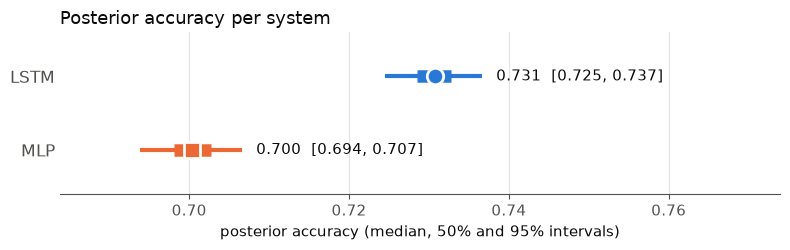

In [26]:
acc = np.asarray(posterior["accuracy"])                        # [samples, systems]
fig, ax = plt.subplots(figsize=(8, 2.6))
for y, name in enumerate(SYSTEM_NAMES):
    a = acc[:, y]
    lo95, lo50, med, hi50, hi95 = np.percentile(a, [2.5, 25, 50, 75, 97.5])
    ax.hlines(y, lo95, hi95, color=COLORS[name], lw=3)
    ax.hlines(y, lo50, hi50, color=COLORS[name], lw=9)
    ax.scatter(med, y, s=140, color=COLORS[name], marker=MARKERS[name], edgecolor="#fcfcfb", linewidth=2, zorder=3)
    ax.annotate(f"{med:.3f}  [{lo95:.3f}, {hi95:.3f}]", (hi95, y), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=11, color=INK)
ax.set_yticks(range(len(SYSTEM_NAMES)), SYSTEM_NAMES, fontsize=12)
ax.set_ylim(-0.6, len(SYSTEM_NAMES) - 0.4)
ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", labelsize=11)
ax.spines[["left"]].set_visible(False)
ax.set_xlim(acc.min() - 0.005, acc.max() + 0.03)              # room for the value labels
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_xlabel("posterior accuracy (median, 50% and 95% intervals)", fontsize=11)
ax.set_title("Posterior accuracy per system", loc="left", color=INK, fontsize=13)
fig.tight_layout(); plt.show()

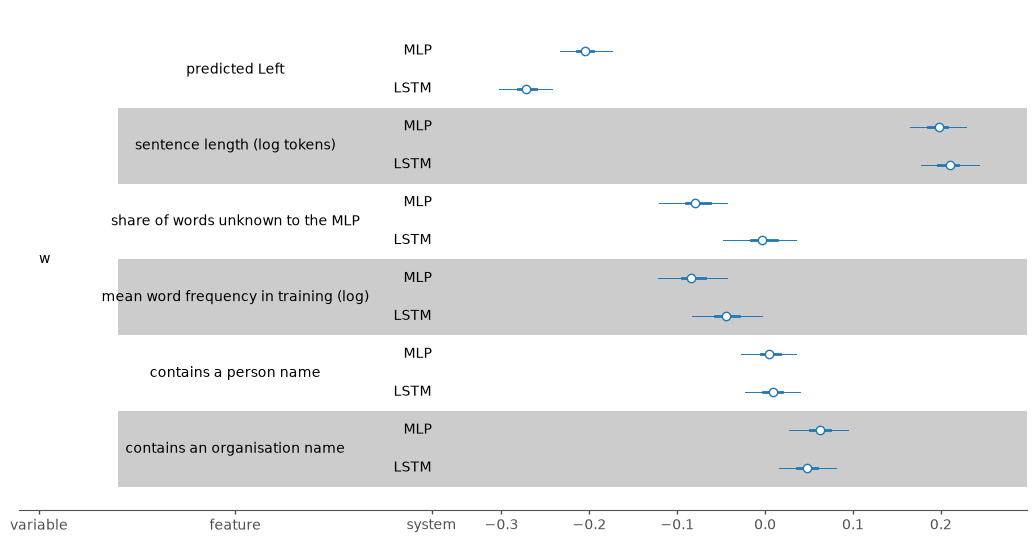

In [27]:
plot_data = posterior_data.copy()
plot_data["posterior"] = posterior_data.posterior["w"].transpose("chain", "draw", "feature", "system").to_dataset()
az.plot_forest(plot_data, var_names=["w"], combined=True, shade_label="feature",
               figure_kwargs={"figsize": (13, 6.5), "width_ratios": [3, 4], "layout": "none"}, **az_stats_params)
fig = plt.gcf()
fig.axes[-1].set_xlabel("feature weight: change in log-odds of a correct prediction per standard deviation of the feature")
fig.suptitle("Feature weights per system (median, 50% and 95% intervals)", fontsize=13, x=0.02, ha="left")
plt.show()

### Weight differences

In [28]:
def summarise(samples, names):
    samples = np.asarray(samples)
    lo, hi = np.percentile(samples, [2.5, 97.5], axis=0)
    return pd.DataFrame({"mean": samples.mean(0), "2.5%": lo, "97.5%": hi, "P(> 0)": (samples > 0).mean(0)},
                        index=names)

w = np.asarray(posterior["w"])                                 # [samples, systems, features]
weights = pd.concat({name: summarise(w[:, s], LABELS) for s, name in enumerate(SYSTEM_NAMES)}, axis=1)
print("feature weights per system (logit per standard deviation):")
print(weights.round(3).to_string())

w_diff = summarise(w[:, 1] - w[:, 0], LABELS)
print("\nLSTM - MLP weight difference:")
print(w_diff.round(3).to_string())

acc = np.asarray(posterior["accuracy"])
acc_diff = summarise((acc[:, 1] - acc[:, 0])[:, None], ["accuracy LSTM - MLP"])
print(); print(acc_diff.round(4).to_string())

feature weights per system (logit per standard deviation):
                                         MLP                        LSTM                     
                                        mean   2.5%  97.5% P(> 0)   mean   2.5%  97.5% P(> 0)
predicted Left                        -0.204 -0.234 -0.175  0.000 -0.272 -0.303 -0.242  0.000
sentence length (log tokens)           0.198  0.166  0.230  1.000  0.210  0.176  0.242  1.000
share of words unknown to the MLP     -0.080 -0.119 -0.040  0.000 -0.004 -0.046  0.037  0.436
mean word frequency in training (log) -0.084 -0.124 -0.045  0.000 -0.043 -0.082 -0.003  0.020
contains a person name                 0.005 -0.027  0.036  0.618  0.009 -0.022  0.041  0.707
contains an organisation name          0.063  0.028  0.096  1.000  0.047  0.015  0.080  0.998

LSTM - MLP weight difference:
                                        mean   2.5%  97.5%  P(> 0)
predicted Left                        -0.067 -0.109 -0.024   0.002
sentence length (log tok

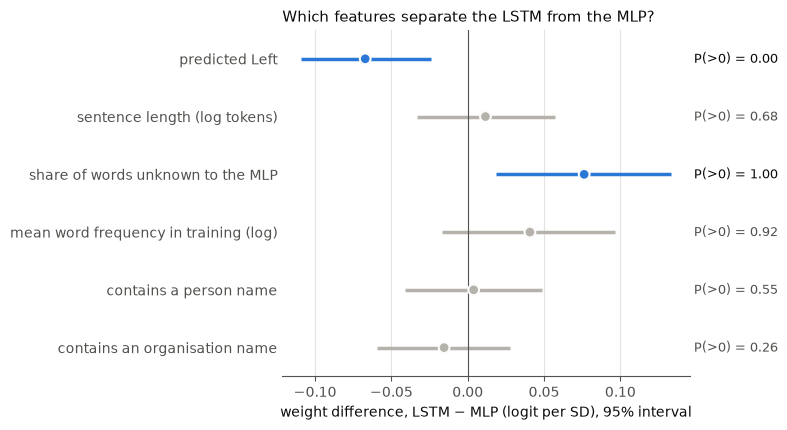

In [29]:
# forest plot of the weight differences, in the style of the plots above
fig, ax = plt.subplots(figsize=(8, 0.5 * len(w_diff) + 1.4))
y = np.arange(len(w_diff))
clear = (w_diff["2.5%"] > 0) | (w_diff["97.5%"] < 0)          # 95% interval excludes 0
colours = np.where(clear, COLORS["LSTM"], "#b4b2ab")
ax.hlines(y, w_diff["2.5%"], w_diff["97.5%"], color=colours, lw=2.5)
ax.scatter(w_diff["mean"], y, color=colours, s=60, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_yticks(y, w_diff.index); ax.set_ylim(len(w_diff) - 0.5, -0.5); ax.tick_params(axis="y", length=0)
ax.spines[["left"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_xlabel("weight difference, LSTM − MLP (logit per SD), 95% interval")
ax.set_title("Which features separate the LSTM from the MLP?", loc="left", color=INK, fontsize=11)
for yi, (_, r) in zip(y, w_diff.iterrows()):
    ax.annotate(f"P(>0) = {r['P(> 0)']:.2f}", (1.01, yi), xycoords=("axes fraction", "data"), va="center",
                fontsize=9, color=INK if clear.loc[_] else INK_2)
fig.tight_layout(); plt.show()

### Regression results

## Summary